# EDA

bla bla bla

#### Importar librerías

In [1]:
import pandas as pd
from pathlib import Path

#### Obtener el path a todos los archivos con raw data

In [2]:
viajes_path = Path("../Data/Viajes_ECOBICI")
estaciones_path = Path("../Data/Estaciones_ECOBICI")

archivos_viajes = sorted(viajes_path.glob("*.csv"))
archivos_estaciones = list(estaciones_path.glob("*.csv"))

print(f"Archivos de viajes: {len(archivos_viajes)}")
print(f"Archivos de estaciones: {len(archivos_estaciones)}")

Archivos de viajes: 24
Archivos de estaciones: 1


#### Entender estructura del primer archivo de viajes

In [3]:
df = pd.read_csv(archivos_viajes[0], nrows=10_000)
df.head()

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
0,M,27,4457313,071,30/09/2024,23:30:05,561,01/10/2024,00:00:00
1,M,29,5785761,254,30/09/2024,23:53:21,031,01/10/2024,00:00:00
2,M,27,6661136,071,30/09/2024,23:28:44,561,01/10/2024,00:00:03
3,M,51,5564174,008,30/09/2024,23:46:23,144,01/10/2024,00:00:09
4,M,19,5208806,119,30/09/2024,23:29:58,520,01/10/2024,00:00:14


In [6]:
df.shape
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Genero_Usuario         10000 non-null  str  
 1   Edad_Usuario           10000 non-null  int64
 2   Bici                   10000 non-null  int64
 3   Ciclo_Estacion_Retiro  10000 non-null  str  
 4   Fecha_Retiro           10000 non-null  str  
 5   Hora_Retiro            10000 non-null  str  
 6   Ciclo_EstacionArribo   10000 non-null  str  
 7   Fecha_Arribo           10000 non-null  str  
 8   Hora_Arribo            10000 non-null  str  
dtypes: int64(2), str(7)
memory usage: 703.3 KB


Genero_Usuario           0
Edad_Usuario             0
Bici                     0
Ciclo_Estacion_Retiro    0
Fecha_Retiro             0
Hora_Retiro              0
Ciclo_EstacionArribo     0
Fecha_Arribo             0
Hora_Arribo              0
dtype: int64

#### Entender estructura del archivo de estaciones

In [8]:
estaciones = pd.read_csv(archivos_estaciones[0], encoding="latin-1")
estaciones.head()

,sistema,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus
0,Ecobici,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada
1,Ecobici,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada
2,Ecobici,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.364730,-99.174447,Arroyo,Instalada
3,Ecobici,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada
4,Ecobici,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada


In [9]:
estaciones.info()

<class 'pandas.DataFrame'>
RangeIndex: 989 entries, 0 to 988
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   sistema     677 non-null    str    
 1   num_cicloe  677 non-null    str    
 2   calle_prin  677 non-null    str    
 3   calle_secu  677 non-null    str    
 4   colonia     677 non-null    str    
 5   alcaldia    677 non-null    str    
 6   latitud     677 non-null    float64
 7   longitud    677 non-null    float64
 8   sitio_de_e  677 non-null    str    
 9   estatus     677 non-null    str    
dtypes: float64(2), str(8)
memory usage: 77.4 KB


#### Limpieza inicial de datos de estaciones

In [10]:
# Revisar filas completamente vacías
estaciones.isna().all(axis=1).sum()

np.int64(312)

In [12]:
# Eliminar filas completamente vacías
estaciones = estaciones.dropna(how="all").copy()

# Revisar estaciones y posibles duplicados
print("Dimensiones:", estaciones.shape)
print("IDs únicos:", estaciones["num_cicloe"].nunique())

Dimensiones: (677, 10)
IDs únicos: 677


#### Comprobar que todas la estructura de todos los archivos de viajes es similar

In [14]:
columnas_por_archivo = {}

for archivo in archivos_viajes:
    columnas = pd.read_csv(archivo, nrows=0).columns.tolist()
    columnas_por_archivo[archivo.name] = columnas

estructuras = pd.DataFrame({
    "archivo": list(columnas_por_archivo.keys()),
    "columnas": list(columnas_por_archivo.values())
})

estructuras["n_columnas"] = estructuras["columnas"].apply(len)

estructuras

,archivo,columnas,n_columnas
0,2024-10.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
1,2024-11.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
2,2024-12.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
3,2025-01.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
4,2025-02.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
5,2025-03.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
6,2025-04.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
7,2025-05.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
8,2025-06.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9
9,2025-07.csv,"[Genero_Usuario, Edad_Usuario, Bici, Ciclo_Est...",9


### EDA v1 — Inspección inicial de datos

**Datos de viajes**

Se inició la exploración con una muestra de 10,000 registros de octubre de 2024. Se identificaron nueve columnas, incluyendo identificadores de estaciones de origen y destino, así como fechas y horas de retiro y arribo.

No se encontraron valores faltantes en la muestra inicial. Esto todavía no permite concluir que los archivos completos estén libres de valores nulos.

**Catálogo de estaciones**

El catálogo contiene 989 filas, pero solamente 677 registros con información en las diez columnas. Se investigará si las 312 filas restantes están completamente vacías.

Se identificaron las variables geográficas necesarias para vincular las estaciones con su entorno urbano.

**Consideraciones para el procesamiento**

- Conservar los identificadores de estaciones como cadenas de texto.
- Verificar la consistencia de columnas entre los 24 archivos mensuales.
- Examinar los viajes que cruzan límites entre meses.
- Validar los identificadores del catálogo antes de unir los datasets.

In [17]:
# Comprobar que todas las estructuras son similares (si devuelve 1, los 24 archivos tienen exactamente las mismas columnas en el mismo orden)
estructuras["columnas"].apply(tuple).nunique()

1

In [18]:
estaciones["estatus"].value_counts(dropna=False)

estatus
Instalada    677
Name: count, dtype: int64

In [19]:
print("IDs del catálogo:")
print(estaciones["num_cicloe"].head(10).tolist())

print("\nIDs de retiro:")
print(df["Ciclo_Estacion_Retiro"].head(10).tolist())

print("\nIDs de arribo:")
print(df["Ciclo_EstacionArribo"].head(10).tolist())

IDs del catálogo:
['423', '437', '438', '439', '440', '415', '420', '421', '422', '436']

IDs de retiro:
['071', '254', '071', '008', '119', '452', '638', '003', '369', '295']

IDs de arribo:
['561', '031', '561', '144', '520', '041', '644', '331', '683', '597']


In [20]:
ids_catalogo = set(estaciones["num_cicloe"])

ids_viajes = set(df["Ciclo_Estacion_Retiro"]) | set(df["Ciclo_EstacionArribo"])

print("Estaciones diferentes en la muestra:", len(ids_viajes))
print("Estaciones que coinciden:", len(ids_viajes & ids_catalogo))
print("Estaciones sin coincidencia:", len(ids_viajes - ids_catalogo))

Estaciones diferentes en la muestra: 678
Estaciones que coinciden: 677
Estaciones sin coincidencia: 1


### EDA v1 — Consistencia estructural

Se verificaron los encabezados de los 24 archivos mensuales correspondientes al periodo octubre de 2024–septiembre de 2026. Todos contienen nueve columnas con nombres y orden consistentes.

En el catálogo de estaciones se identificaron 312 filas completamente vacías, las cuales fueron eliminadas. El catálogo resultante contiene 677 registros con identificadores únicos.

**Siguientes verificaciones:**
- Revisar el estatus de las estaciones.
- Evaluar la compatibilidad entre identificadores del catálogo y registros de viajes.
- Verificar posteriormente la calidad de los archivos históricos completos.

In [21]:
# Identificar estaciones que no aparecen en el catálogo
ids_faltantes = ids_viajes - ids_catalogo

print("IDs sin coincidencia:", ids_faltantes)

IDs sin coincidencia: {'1000'}


In [22]:
print("Retiros:", (df["Ciclo_Estacion_Retiro"] == "1000").sum())
print("Arribos:", (df["Ciclo_EstacionArribo"] == "1000").sum())

Retiros: 0
Arribos: 2


In [23]:
df[
    (df["Ciclo_Estacion_Retiro"] == "1000") |
    (df["Ciclo_EstacionArribo"] == "1000")
].head(10)

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
98,M,34,2216190,017,25/09/2024,08:01:26,1000,01/10/2024,00:12:59
344,F,38,7361033,556,30/09/2024,23:17:01,1000,01/10/2024,02:21:13


### Hallazgo: identificador de estación 1000

Durante la inspección de los primeros 10,000 registros de octubre de 2024, se identificó el código `1000`, que no tiene correspondencia en el catálogo de 677 estaciones.

Este identificador aparece en dos registros como estación de arribo y en ninguno como estación de retiro. Ambos viajes presentan duraciones prolongadas, incluyendo uno superior a cinco días.

Se desconoce todavía el significado operativo de este identificador.

**Decisión preliminar:** conservar los registros originales y no considerar `1000` como una estación geográfica válida. Su tratamiento definitivo dependerá de la revisión de los archivos completos y de las reglas de limpieza de viajes.

#### Explorar volumen histórico de viajes


In [24]:
resumen = []

for archivo in archivos_viajes:
    n_viajes = 0
    for chunk in pd.read_csv(
        archivo,
        usecols=["Fecha_Arribo"],
        chunksize=250_000
    ):
        n_viajes += len(chunk)
    resumen.append({
        "mes": archivo.stem,
        "viajes": n_viajes
    })

resumen = pd.DataFrame(resumen)
resumen

,mes,viajes
0,2024-10,2054609
1,2024-11,1942474
2,2024-12,1680650
3,2025-01,1809775
4,2025-02,1745620
5,2025-03,1832587
6,2025-04,1727987
7,2025-05,1778594
8,2025-06,1578804
9,2025-07,1663896


In [25]:
print(f"Total de registros: {resumen['viajes'].sum():,}")
print(f"Promedio mensual: {resumen['viajes'].mean():,.0f}")

Total de registros: 39,690,611
Promedio mensual: 1,653,775


Matplotlib is building the font cache; this may take a moment.


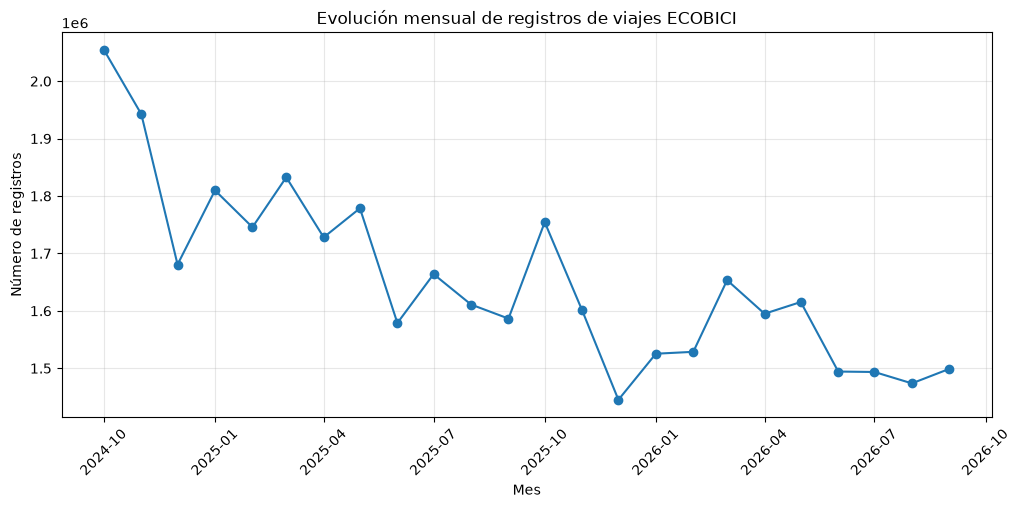

In [27]:
import matplotlib.pyplot as plt

resumen["mes"] = pd.to_datetime(resumen["mes"], format="%Y-%m")

plt.figure(figsize=(12, 5))

plt.plot(resumen["mes"], resumen["viajes"], marker="o")

plt.title("Evolución mensual de registros de viajes ECOBICI")
plt.xlabel("Mes")
plt.ylabel("Número de registros")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [28]:
resumen.sort_values("viajes").head()

,mes,viajes
14,2025-12-01,1445068
22,2026-08-01,1473683
21,2026-07-01,1493484
20,2026-06-01,1494265
23,2026-09-01,1498934


In [29]:
resumen.sort_values("viajes", ascending=False).head()

,mes,viajes
0,2024-10-01,2054609
1,2024-11-01,1942474
5,2025-03-01,1832587
3,2025-01-01,1809775
7,2025-05-01,1778594


### EDA v1 — Evolución mensual de viajes

**Objetivo:** analizar el volumen de registros de viajes de ECOBICI entre octubre de 2024 y septiembre de 2026.

Se contabilizarán los registros de cada archivo mensual y se explorará su evolución temporal.

**Consideraciones metodológicas:**
- El número de registros mensuales no necesariamente representa la demanda subyacente del sistema.
- Se deberá comprobar si los archivos están organizados por fecha de retiro o de arribo.
- Las comparaciones deberán considerar diferencias en días por mes y posibles cambios en el número de estaciones operativas.
- Las tendencias observadas se interpretarán inicialmente como descriptivas, no causales.

In [30]:
resumen["dias_mes"] = resumen["mes"].dt.days_in_month
resumen["viajes_diarios"] = resumen["viajes"] / resumen["dias_mes"]

resumen[["mes", "viajes", "viajes_diarios"]]

,mes,viajes,viajes_diarios
0,2024-10-01,2054609,66277.709677
1,2024-11-01,1942474,64749.133333
2,2024-12-01,1680650,54214.516129
3,2025-01-01,1809775,58379.838710
4,2025-02-01,1745620,62343.571429
5,2025-03-01,1832587,59115.709677
6,2025-04-01,1727987,57599.566667
7,2025-05-01,1778594,57374.000000
8,2025-06-01,1578804,52626.800000
9,2025-07-01,1663896,53674.064516


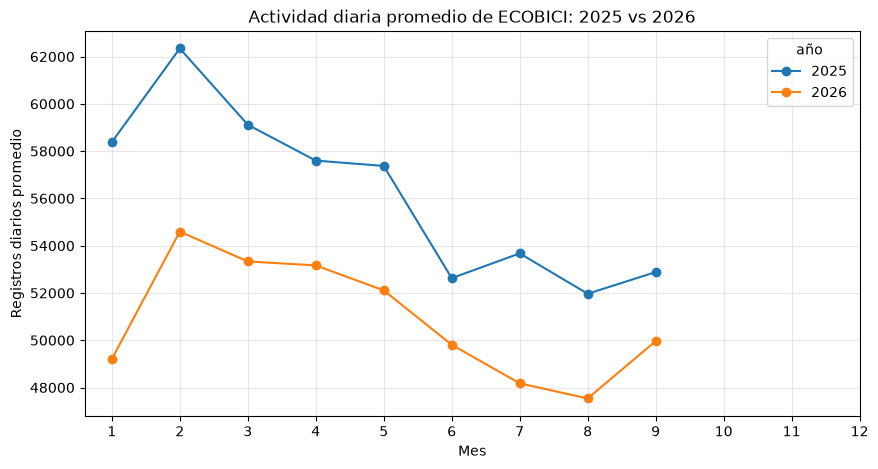

In [31]:
resumen["año"] = resumen["mes"].dt.year
resumen["num_mes"] = resumen["mes"].dt.month

comparacion = resumen.pivot(
    index="num_mes",
    columns="año",
    values="viajes_diarios"
)

comparacion[[2025, 2026]].dropna().plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Actividad diaria promedio de ECOBICI: 2025 vs 2026")
plt.xlabel("Mes")
plt.ylabel("Registros diarios promedio")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

In [32]:
comparacion["crecimiento_2026"] = (
    comparacion[2026] / comparacion[2025] - 1
) * 100

comparacion[[2025, 2026, "crecimiento_2026"]].dropna().round(2)

año,2025,2026,crecimiento_2026
num_mes,,,
1,58379.84,49203.29,-15.72
2,62343.57,54593.21,-12.43
3,59115.71,53334.61,-9.78
4,57599.57,53165.57,-7.70
5,57374.00,52108.39,-9.18
6,52626.80,49808.83,-5.35
7,53674.06,48176.90,-10.24
8,51966.68,47538.16,-8.52
9,52883.60,49964.47,-5.52


In [33]:
for archivo in [archivos_viajes[0], archivos_viajes[-1]]:

    muestra = pd.read_csv(
        archivo,
        usecols=["Fecha_Retiro", "Fecha_Arribo"],
        nrows=10_000
    )

    muestra["Fecha_Retiro"] = pd.to_datetime(
        muestra["Fecha_Retiro"], dayfirst=True
    )

    muestra["Fecha_Arribo"] = pd.to_datetime(
        muestra["Fecha_Arribo"], dayfirst=True
    )

    print(f"\nArchivo: {archivo.name}")

    print("Fechas de retiro:")
    print(muestra["Fecha_Retiro"].min(), muestra["Fecha_Retiro"].max())

    print("Fechas de arribo:")
    print(muestra["Fecha_Arribo"].min(), muestra["Fecha_Arribo"].max())


Archivo: 2024-10.csv
Fechas de retiro:
2024-09-25 00:00:00 2024-10-01 00:00:00
Fechas de arribo:
2024-10-01 00:00:00 2024-10-01 00:00:00

Archivo: 2026-09.csv
Fechas de retiro:
2026-08-31 00:00:00 2026-09-01 00:00:00
Fechas de arribo:
2026-09-01 00:00:00 2026-09-01 00:00:00


### Comparación interanual 2025–2026

Se comparó el promedio diario de registros de viajes entre enero y septiembre de 2025 y 2026.

Los nueve meses analizados presentaron variaciones interanuales negativas, desde −5.35% hasta −15.72%.

Este resultado muestra una disminución consistente en el volumen de registros del sistema, incluso después de ajustar por la cantidad de días calendario de cada mes.

**Hipótesis para investigar:** la evolución agregada podría ocultar diferencias importantes entre estaciones y zonas geográficas, incluyendo algunas con crecimiento positivo.

Antes de interpretar los resultados como cambios en la demanda, será necesario verificar la asignación temporal de los viajes, la integridad de los registros y posibles cambios operativos.

In [34]:
octubre = pd.read_csv(
    archivos_viajes[0],
    usecols=["Fecha_Retiro", "Fecha_Arribo"]
)

octubre["Fecha_Retiro"] = pd.to_datetime(
    octubre["Fecha_Retiro"],
    format="%d/%m/%Y",
    errors="coerce"
)

octubre["Fecha_Arribo"] = pd.to_datetime(
    octubre["Fecha_Arribo"],
    format="%d/%m/%Y",
    errors="coerce"
)

In [35]:
octubre.agg(["min", "max"])

,Fecha_Retiro,Fecha_Arribo
min,2024-03-04,2024-10-01
max,2024-10-31,2024-10-31


In [36]:
print(
    "Arribos fuera de octubre:",
    (octubre["Fecha_Arribo"].dt.to_period("M") != "2024-10").sum()
)

print(
    "Retiros fuera de octubre:",
    (octubre["Fecha_Retiro"].dt.to_period("M") != "2024-10").sum()
)

print("\nFechas inválidas:")
print(octubre.isna().sum())

Arribos fuera de octubre: 0
Retiros fuera de octubre: 127

Fechas inválidas:
Fecha_Retiro    0
Fecha_Arribo    0
dtype: int64


In [37]:
retiros_fuera = octubre[
    octubre["Fecha_Retiro"] < "2024-10-01"
]

retiros_fuera["Fecha_Retiro"].dt.to_period("M").value_counts().sort_index()

Fecha_Retiro
2024-03      1
2024-06      1
2024-08      1
2024-09    124
Freq: M, Name: count, dtype: int64

In [38]:
octubre["duracion_dias"] = (
    octubre["Fecha_Arribo"] - octubre["Fecha_Retiro"]
).dt.days

octubre["duracion_dias"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
)

count    2.054609e+06
mean     2.805887e-03
std      1.946832e-01
min      0.000000e+00
90%      0.000000e+00
95%      0.000000e+00
99%      0.000000e+00
99.9%    1.000000e+00
max      2.180000e+02
Name: duracion_dias, dtype: float64

In [39]:
octubre["duracion_dias"] = (
    octubre["Fecha_Arribo"] - octubre["Fecha_Retiro"]
).dt.days

octubre["duracion_dias"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
)

count    2.054609e+06
mean     2.805887e-03
std      1.946832e-01
min      0.000000e+00
90%      0.000000e+00
95%      0.000000e+00
99%      0.000000e+00
99.9%    1.000000e+00
max      2.180000e+02
Name: duracion_dias, dtype: float64

In [40]:
octubre.sort_values(
    "duracion_dias",
    ascending=False
).head(10)

,Fecha_Retiro,Fecha_Arribo,duracion_dias
461650,2024-03-04,2024-10-08,218
1730814,2024-06-23,2024-10-27,126
786020,2024-08-01,2024-10-13,73
1281092,2024-09-24,2024-10-20,26
1768674,2024-10-03,2024-10-28,25
116904,2024-09-08,2024-10-02,24
510304,2024-09-17,2024-10-09,22
1377002,2024-10-04,2024-10-22,18
466658,2024-09-21,2024-10-08,17
1282546,2024-10-06,2024-10-21,15


In [41]:
conteos = []

for archivo in archivos_viajes:
    print(f"Procesando {archivo.name}")

    for chunk in pd.read_csv(
        archivo,
        usecols=[
            "Ciclo_Estacion_Retiro",
            "Ciclo_EstacionArribo",
            "Fecha_Retiro",
            "Fecha_Arribo"
        ],
        dtype={
            "Ciclo_Estacion_Retiro": "string",
            "Ciclo_EstacionArribo": "string"
        },
        chunksize=250_000
    ):

        for tipo, estacion, fecha in [
            ("retiros", "Ciclo_Estacion_Retiro", "Fecha_Retiro"),
            ("arribos", "Ciclo_EstacionArribo", "Fecha_Arribo")
        ]:

            fechas = pd.to_datetime(
                chunk[fecha],
                format="%d/%m/%Y",
                errors="coerce"
            )

            datos = pd.DataFrame({
                "mes": fechas.dt.to_period("M").astype("string"),
                "estacion": chunk[estacion].str.strip()
            })

            filtro = (
                fechas.between("2024-10-01", "2026-09-30")
                & datos["estacion"].notna()
            )

            conteo = (
                datos[filtro]
                .groupby(["mes", "estacion"])
                .size()
                .reset_index(name="cantidad")
            )

            conteo["tipo"] = tipo
            conteos.append(conteo)

Procesando 2024-10.csv
Procesando 2024-11.csv
Procesando 2024-12.csv
Procesando 2025-01.csv
Procesando 2025-02.csv
Procesando 2025-03.csv
Procesando 2025-04.csv
Procesando 2025-05.csv
Procesando 2025-06.csv
Procesando 2025-07.csv
Procesando 2025-08.csv
Procesando 2025-09.csv
Procesando 2025-10.csv
Procesando 2025-11.csv
Procesando 2025-12.csv
Procesando 2026-01.csv
Procesando 2026-02.csv
Procesando 2026-03.csv
Procesando 2026-04.csv
Procesando 2026-05.csv
Procesando 2026-06.csv
Procesando 2026-07.csv
Procesando 2026-08.csv
Procesando 2026-09.csv


In [42]:
actividad = pd.concat(conteos, ignore_index=True)

actividad = (
    actividad
    .groupby(["mes", "estacion", "tipo"])["cantidad"]
    .sum()
    .unstack("tipo", fill_value=0)
    .reset_index()
)

actividad.columns.name = None

actividad["movimientos"] = (
    actividad["retiros"] + actividad["arribos"]
)

actividad = actividad.sort_values(
    ["mes", "estacion"]
).reset_index(drop=True)

actividad.head()

,mes,estacion,arribos,retiros,movimientos
0,2024-10,001,9070,8787,17857
1,2024-10,002,3734,3543,7277
2,2024-10,003,3746,4056,7802
3,2024-10,004,5040,4761,9801
4,2024-10,005,5354,5454,10808


In [43]:
print("Dimensiones:", actividad.shape)
print("Meses:", actividad["mes"].nunique())
print("Estaciones:", actividad["estacion"].nunique())

actividad[["retiros", "arribos", "movimientos"]].describe()

Dimensiones: (16270, 5)
Meses: 24
Estaciones: 683


,retiros,arribos,movimientos
count,16270.000000,16270.000000,16270.000000
mean,2439.487154,2439.496681,4878.983835
std,1593.510929,1760.342531,3326.546316
min,0.000000,2.000000,2.000000
25%,1316.250000,1289.000000,2604.250000
50%,2041.000000,1986.000000,4037.000000
75%,3093.000000,3074.000000,6163.750000
max,24459.000000,37110.000000,61569.000000


In [44]:
ids_actividad = set(actividad["estacion"])
ids_catalogo = set(estaciones["num_cicloe"])

print("En viajes, pero no en catálogo:")
print(sorted(ids_actividad - ids_catalogo))

print("\nEn catálogo, pero no en viajes:")
print(sorted(ids_catalogo - ids_actividad))

En viajes, pero no en catálogo:
['1000', 'Temporal - 2da Sección Bosque Chapultepec', 'Temporal 1', 'Temporal 2', 'Temporal 3', 'Temporal 4']

En catálogo, pero no en viajes:
[]


In [45]:
print("Viajes originales:", resumen["viajes"].sum())
print("Arribos agregados:", actividad["arribos"].sum())
print("Retiros agregados:", actividad["retiros"].sum())

Viajes originales: 39690611
Arribos agregados: 39690611
Retiros agregados: 39690456


In [48]:
from pathlib import Path

Path("../data/Procesados").mkdir(parents=True, exist_ok=True)

actividad.to_csv(
    "../data/Procesados/actividad_mensual_ECOBICI.csv",
    index=False
)

### EDA v1 — Consolidación de actividad mensual

Se procesaron 39,690,611 registros históricos correspondientes al periodo octubre de 2024–septiembre de 2026.

Se construyó un dataset agregado con 16,270 observaciones, correspondientes a combinaciones de estación y mes, incluyendo 683 identificadores de estación distintos.

**Validación:**
- Los arribos agregados coinciden exactamente con el total de registros originales.
- Se registraron 155 retiros menos que arribos, una diferencia equivalente al 0.00039% del total.
- Se identificaron seis códigos de estación sin correspondencia en el catálogo geográfico: `1000` y cinco identificadores de estaciones temporales.
- Las 677 estaciones del catálogo aparecen en los registros históricos.

**Decisiones:**
- Conservar los identificadores especiales en el dataset de actividad.
- Excluirlos provisionalmente de análisis que requieren coordenadas geográficas.
- Mantener documentadas las anomalías temporales para posteriores análisis de sensibilidad.

El dataset resultante se almacenó como `data/processed/actividad_mensual.csv`.

In [49]:
# Trabajar únicamente con estaciones del catálogo geográfico
actividad_geo = actividad[
    actividad["estacion"].isin(estaciones["num_cicloe"])
].copy()

# Número de meses con registros por estación
meses_por_estacion = actividad_geo.groupby("estacion")["mes"].nunique()

print(meses_por_estacion.value_counts().sort_index())

mes
21      2
22      1
23      4
24    670
Name: count, dtype: int64


In [50]:
# Conservar estaciones con registros en los 24 meses
estaciones_completas = meses_por_estacion[
    meses_por_estacion == 24
].index

crecimiento = actividad_geo[
    actividad_geo["estacion"].isin(estaciones_completas)
].copy()

# Identificar periodo
crecimiento["periodo"] = crecimiento["mes"].apply(
    lambda x: "2024-2025" if x < "2025-10" else "2025-2026"
)

# Calcular movimientos diarios promedio
crecimiento = (
    crecimiento.groupby(["estacion", "periodo"])["movimientos"]
    .sum()
    .unstack()
    / 365
)

# Calcular crecimiento porcentual y absoluto
crecimiento["crecimiento_pct"] = (
    crecimiento["2025-2026"] / crecimiento["2024-2025"] - 1
) * 100

crecimiento["diferencia_diaria"] = (
    crecimiento["2025-2026"] - crecimiento["2024-2025"]
)

crecimiento.head()

periodo,2024-2025,2025-2026,crecimiento_pct,diferencia_diaria
estacion,,,,
001,500.528767,429.852055,-14.120410,-70.676712
002,205.657534,179.065753,-12.930127,-26.591781
003,224.372603,213.183562,-4.986813,-11.189041
004,282.843836,242.901370,-14.121738,-39.942466
005,295.147945,264.983562,-10.220089,-30.164384


In [51]:
crecimiento.describe().round(2)

periodo,2024-2025,2025-2026,crecimiento_pct,diferencia_diaria
count,670.00,670.00,670.00,670.00
mean,170.31,151.77,-9.21,-18.54
std,116.18,96.92,8.27,26.20
min,19.93,16.81,-44.30,-325.65
25%,90.63,83.40,-14.29,-26.71
50%,138.28,128.53,-9.78,-12.07
75%,208.90,193.28,-4.31,-4.34
max,1217.87,892.22,30.70,24.23


In [52]:
print("Estaciones analizadas:", len(crecimiento))

print(
    "Estaciones con crecimiento:",
    (crecimiento["crecimiento_pct"] > 0).sum()
)

print(
    "Estaciones con disminución:",
    (crecimiento["crecimiento_pct"] < 0).sum()
)

print(
    "Crecimiento mediano:",
    round(crecimiento["crecimiento_pct"].median(), 2), "%"
)

Estaciones analizadas: 670
Estaciones con crecimiento: 83
Estaciones con disminución: 587
Crecimiento mediano: -9.78 %


In [53]:
crecimiento.sort_values(
    "diferencia_diaria",
    ascending=False
).head(10).round(2)

periodo,2024-2025,2025-2026,crecimiento_pct,diferencia_diaria
estacion,,,,
405,189.93,214.16,12.76,24.23
635,201.62,223.92,11.06,22.30
208,492.06,511.90,4.03,19.84
638,159.68,177.33,11.05,17.65
458,56.78,74.21,30.70,17.43
608,173.30,187.73,8.33,14.44
502,159.27,173.56,8.97,14.29
487,83.25,97.50,17.12,14.25
126,221.24,235.18,6.30,13.93


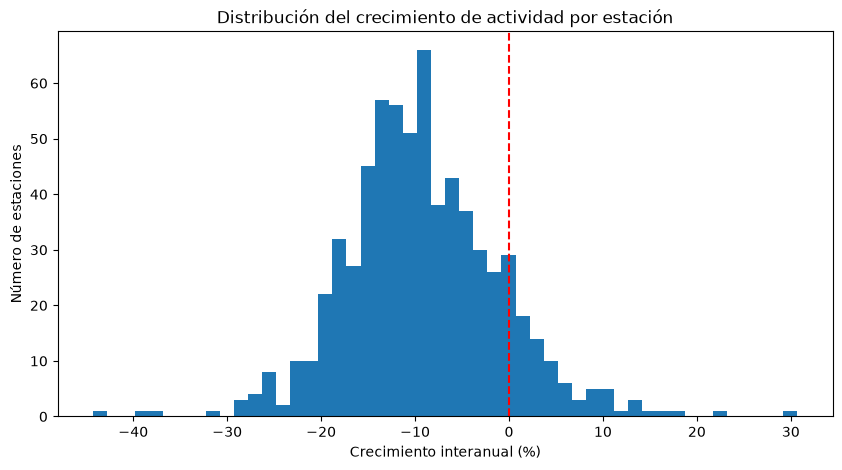

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    crecimiento["crecimiento_pct"].dropna(),
    bins=50
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Distribución del crecimiento de actividad por estación")
plt.xlabel("Crecimiento interanual (%)")
plt.ylabel("Número de estaciones")

plt.show()

## Conclusiones — EDA v1

### Evolución histórica de ECOBICI (octubre 2024–septiembre 2026)

Se analizaron 39,690,611 registros de viajes correspondientes a 24 meses de operación del sistema ECOBICI.

**Principales hallazgos:**

1. La actividad registrada del sistema presentó una tendencia descendente. Los últimos 12 meses registraron aproximadamente 11.1% menos viajes que los primeros 12 meses.

2. Se construyó un dataset de actividad mensual con 16,270 observaciones correspondientes a 683 identificadores de estación.

3. Para el análisis de crecimiento interanual se seleccionaron 670 estaciones del catálogo geográfico con registros en los 24 meses.

4. De estas estaciones, 83 (12.4%) experimentaron crecimiento positivo en movimientos diarios promedio, mientras que 587 (87.6%) registraron disminuciones.

5. El crecimiento mediano fue de −9.78%, aunque se observaron diferencias importantes entre estaciones, con tasas desde −44.30% hasta +30.70%.

### Implicaciones para la investigación

Los resultados sugieren que la disminución agregada de actividad no es homogénea entre estaciones. Esto motiva investigar si existen patrones geográficos y características urbanas asociadas con diferentes niveles y tendencias de utilización.

El siguiente análisis incorporará las coordenadas geográficas de las estaciones para evaluar la distribución espacial de la actividad y su crecimiento.

### Limitaciones preliminares

- Los registros mensuales no necesariamente reflejan cambios en la demanda subyacente.
- La presencia de una estación durante los 24 meses no garantiza operación continua.
- Se identificaron registros temporales atípicos e identificadores especiales que requerirán tratamiento al realizar análisis geográficos.
- El crecimiento histórico observado no permite inferir por sí solo la demanda que generaría una estación nueva.